# 🚲 Urban Mobility Demand Prediction — Exploratory Data Analysis (EDA)

## Project Overview
Urban mobility systems (such as bike sharing and transit networks) require precise demand forecasting to optimize fleet distribution, reduce operational bottlenecks, and enhance user experience. 

This notebook provides a thorough **Exploratory Data Analysis (EDA)** on the Kaggle competition dataset, analyzing:
1. **Target Distribution**: Demand skewness, dispersion, and logarithmic transformation analysis.
2. **Temporal Dynamics**: Diurnal patterns, rush hour spikes, weekday vs weekend behavior, seasonal and annual trends.
3. **Weather Impacts**: Effects of temperature, feels-like temperature, humidity, wind speed, and precipitation.
4. **Feature Correlations**: Multicollinearity analysis and interaction feature discovery.


In [1]:
import os
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

# Visual aesthetics
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'Helvetica'
plt.rcParams['axes.edgecolor'] = '#333333'
plt.rcParams['axes.linewidth'] = 0.8

# Paths
DATA_DIR = Path("../data")
PLOTS_DIR = Path("../outputs/eda_plots")
PLOTS_DIR.mkdir(parents=True, exist_ok=True)

# Load data
train_df = pd.read_csv(DATA_DIR / "train.csv")
test_df = pd.read_csv(DATA_DIR / "test.csv")
sample_sub = pd.read_csv(DATA_DIR / "sample_submission.csv")

print(f"Train Shape: {train_df.shape}")
print(f"Test Shape:  {test_df.shape}")
print(f"Sample Sub:  {sample_sub.shape}")


Train Shape: (12165, 14)
Test Shape:  (5214, 13)
Sample Sub:  (5214, 2)


## 1. Data Inspection & Health Check
Let's inspect the data types, missing values, duplicates, and statistical summaries.


In [2]:
print("--- TRAIN DATA INFO ---")
display(train_df.info())

print("\n--- MISSING VALUES ---")
missing_df = pd.DataFrame({
    'Train Missing': train_df.isnull().sum(),
    'Train Missing (%)': (train_df.isnull().sum() / len(train_df)) * 100,
    'Test Missing': test_df.isnull().sum(),
    'Test Missing (%)': (test_df.isnull().sum() / len(test_df)) * 100
})
display(missing_df[missing_df['Train Missing'] > 0])


--- TRAIN DATA INFO ---
<class 'pandas.DataFrame'>
RangeIndex: 12165 entries, 0 to 12164
Data columns (total 14 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 12165 non-null  int64  
 1   season_code        12165 non-null  int64  
 2   flag_holiday       12165 non-null  int64  
 3   flag_working       12165 non-null  int64  
 4   category_weather   12165 non-null  int64  
 5   feature_temp       12165 non-null  float64
 6   feature_feel_temp  12165 non-null  float64
 7   feature_humidity   11557 non-null  float64
 8   feature_wind       11557 non-null  float64
 9   demand             12165 non-null  int64  
 10  Year               12165 non-null  int64  
 11  Hour               12165 non-null  int64  
 12  Day_of_Week        12165 non-null  int64  
 13  Month              12165 non-null  int64  
dtypes: float64(4), int64(10)
memory usage: 1.3 MB


None


--- MISSING VALUES ---


,Train Missing,Train Missing (%),Test Missing,Test Missing (%)
feature_humidity,608,4.997945,261.0,5.005754
feature_wind,608,4.997945,261.0,5.005754


In [3]:
print("--- STATISTICAL SUMMARY (TRAIN) ---")
display(train_df.describe().T)


--- STATISTICAL SUMMARY (TRAIN) ---


,count,mean,std,min,25%,50%,75%,max
id,12165.0,6083.000000,3511.877347,1.0000,3042.0000,6083.0000,9124.0000,12165.0000
season_code,12165.0,2.500534,1.109777,1.0000,2.0000,3.0000,3.0000,4.0000
flag_holiday,12165.0,0.028442,0.166239,0.0000,0.0000,0.0000,0.0000,1.0000
flag_working,12165.0,0.685656,0.464273,0.0000,0.0000,1.0000,1.0000,1.0000
category_weather,12165.0,1.425072,0.637076,1.0000,1.0000,1.0000,2.0000,4.0000
feature_temp,12165.0,0.497197,0.192414,0.0200,0.3400,0.5000,0.6600,0.9800
feature_feel_temp,12165.0,0.475919,0.171508,0.0152,0.3333,0.4848,0.6212,1.0000
feature_humidity,11557.0,0.626863,0.193058,0.0000,0.4800,0.6300,0.7800,1.0000
feature_wind,11557.0,0.189611,0.121757,0.0000,0.1045,0.1940,0.2537,0.8507
demand,12165.0,279.223263,241.989716,26.0000,79.0000,218.0000,402.0000,1334.0000


## 2. Target Variable Analysis (`demand`)
Understanding the distribution of `demand` is essential for choosing the right objective function and deciding whether a target transformation ($\log(1+y)$) is warranted.


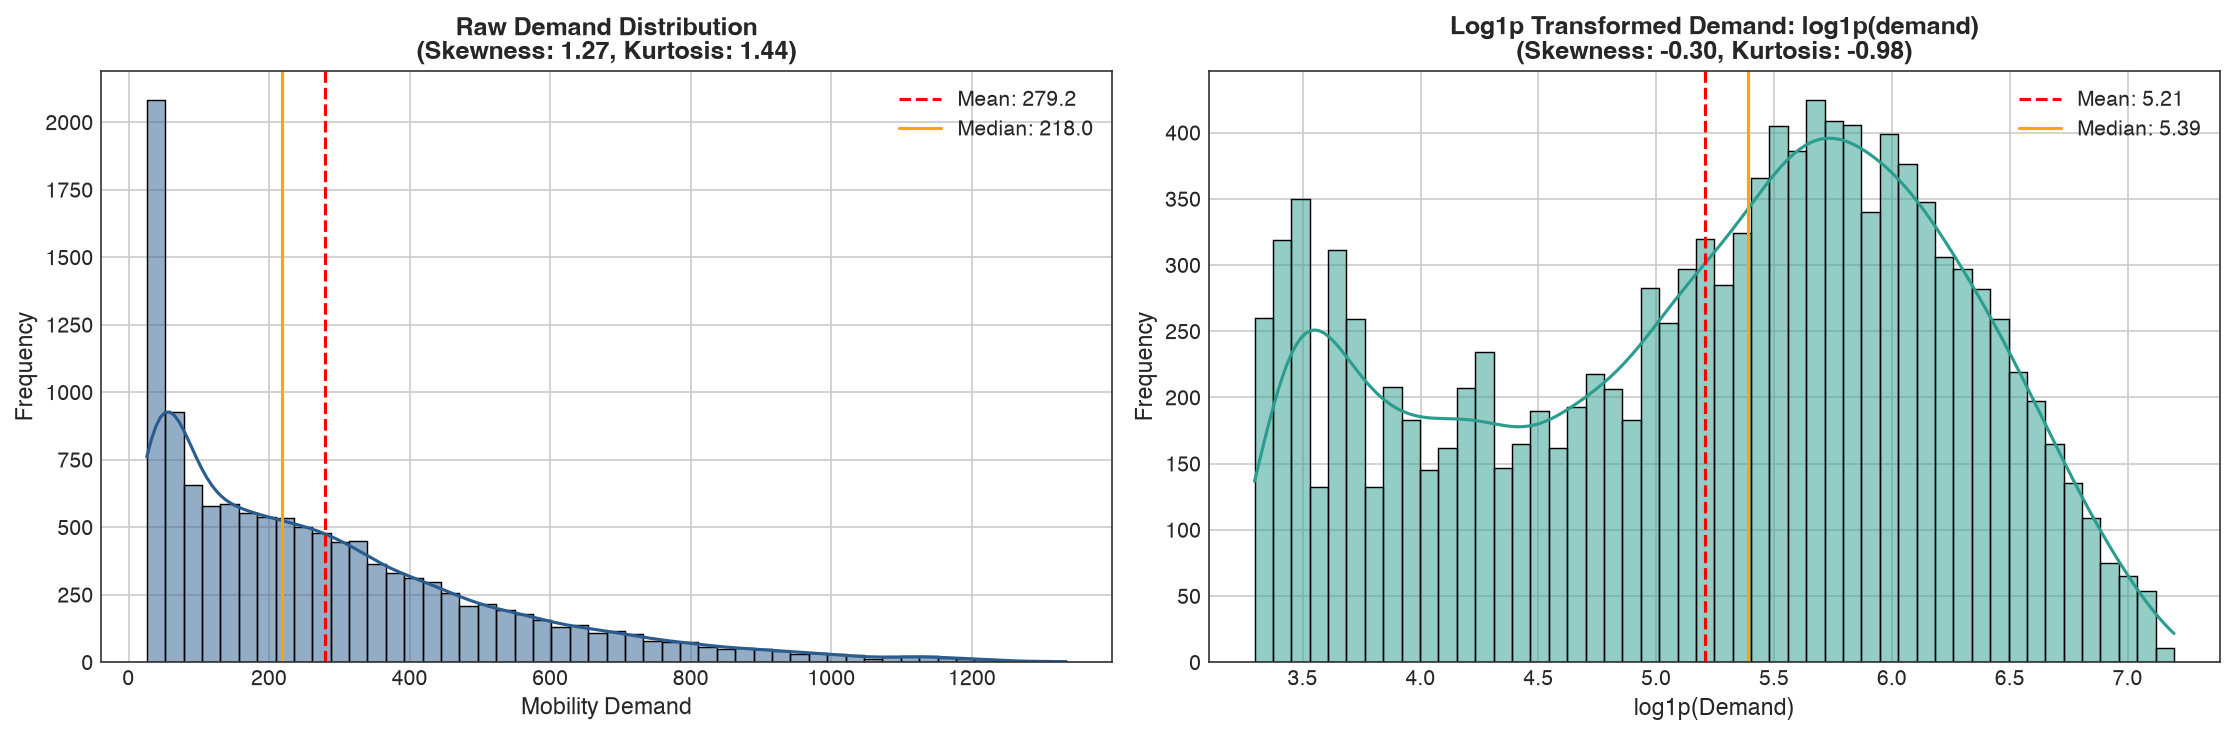

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5), dpi=150)

# Raw Demand
sns.histplot(train_df['demand'], kde=True, ax=axes[0], color='#2b5c8f', bins=50)
axes[0].set_title(f"Raw Demand Distribution\n(Skewness: {train_df['demand'].skew():.2f}, Kurtosis: {train_df['demand'].kurtosis():.2f})", fontsize=12, fontweight='bold')
axes[0].set_xlabel("Mobility Demand", fontsize=11)
axes[0].set_ylabel("Frequency", fontsize=11)
axes[0].axvline(train_df['demand'].mean(), color='red', linestyle='--', label=f"Mean: {train_df['demand'].mean():.1f}")
axes[0].axvline(train_df['demand'].median(), color='orange', linestyle='-', label=f"Median: {train_df['demand'].median():.1f}")
axes[0].legend()

# Log1p Transformed Demand
log_demand = np.log1p(train_df['demand'])
sns.histplot(log_demand, kde=True, ax=axes[1], color='#2a9d8f', bins=50)
axes[1].set_title(f"Log1p Transformed Demand: log1p(demand)\n(Skewness: {log_demand.skew():.2f}, Kurtosis: {log_demand.kurtosis():.2f})", fontsize=12, fontweight='bold')
axes[1].set_xlabel("log1p(Demand)", fontsize=11)
axes[1].set_ylabel("Frequency", fontsize=11)
axes[1].axvline(log_demand.mean(), color='red', linestyle='--', label=f"Mean: {log_demand.mean():.2f}")
axes[1].axvline(log_demand.median(), color='orange', linestyle='-', label=f"Median: {log_demand.median():.2f}")
axes[1].legend()

plt.tight_layout()
plt.savefig(PLOTS_DIR / "demand_distribution.png", bbox_inches='tight')
plt.show()


## 3. Temporal Dynamics & Hourly Patterns
Hourly mobility demand varies heavily depending on whether the day is a **working day** or a **weekend/holiday**. 
- Working days exhibit sharp **bimodal commute peaks** (8:00 AM and 5:00–6:00 PM).
- Non-working days exhibit a smooth **unimodal bell curve** peaking in the afternoon (12:00 PM to 4:00 PM).


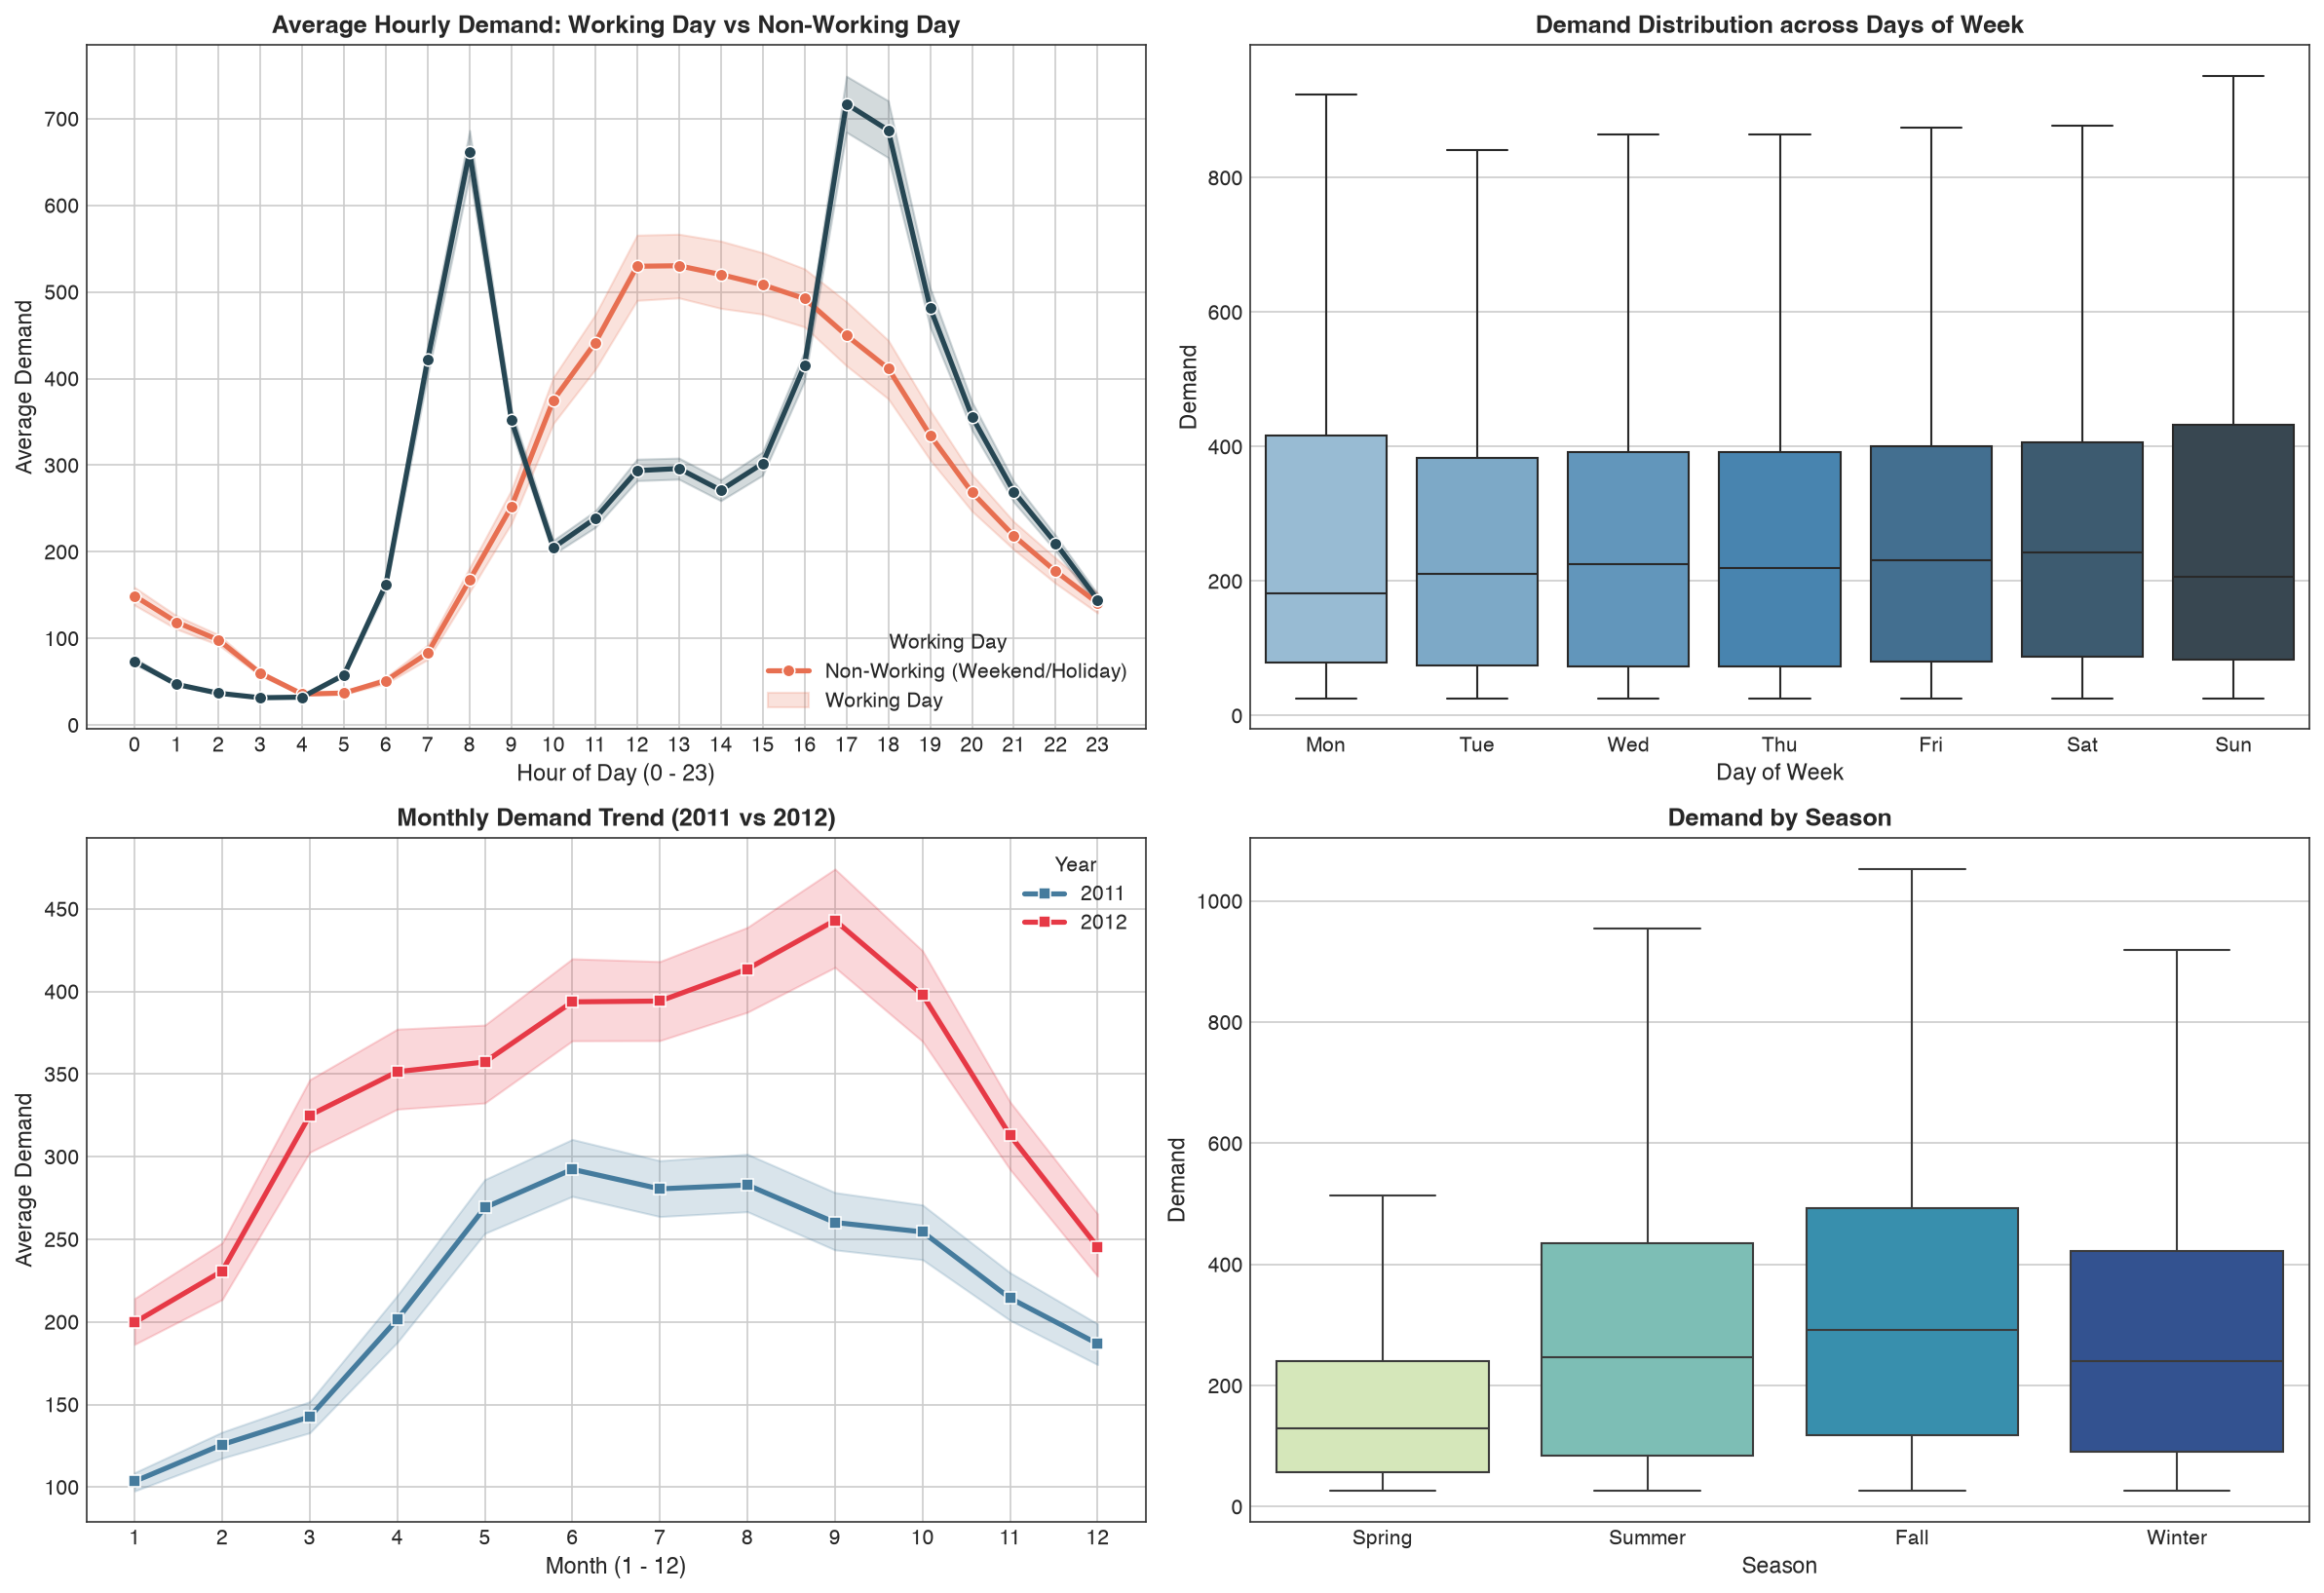

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(16, 11), dpi=150)

# 1. Hourly Demand by Working Day Status
sns.lineplot(data=train_df, x='Hour', y='demand', hue='flag_working', ax=axes[0, 0], palette=['#e76f51', '#264653'], marker='o', linewidth=2.5)
axes[0, 0].set_title("Average Hourly Demand: Working Day vs Non-Working Day", fontsize=12, fontweight='bold')
axes[0, 0].set_xlabel("Hour of Day (0 - 23)", fontsize=11)
axes[0, 0].set_ylabel("Average Demand", fontsize=11)
axes[0, 0].set_xticks(range(0, 24))
axes[0, 0].legend(title="Working Day", labels=["Non-Working (Weekend/Holiday)", "Working Day"])

# 2. Demand by Day of Week
day_names = ['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun']
sns.boxplot(data=train_df, x='Day_of_Week', y='demand', ax=axes[0, 1], palette='Blues_d', showfliers=False)
axes[0, 1].set_title("Demand Distribution across Days of Week", fontsize=12, fontweight='bold')
axes[0, 1].set_xlabel("Day of Week", fontsize=11)
axes[0, 1].set_xticklabels(day_names)
axes[0, 1].set_ylabel("Demand", fontsize=11)

# 3. Monthly Demand Trend by Year
sns.lineplot(data=train_df, x='Month', y='demand', hue='Year', ax=axes[1, 0], palette=['#457b9d', '#e63946'], marker='s', linewidth=2.5)
axes[1, 0].set_title("Monthly Demand Trend (2011 vs 2012)", fontsize=12, fontweight='bold')
axes[1, 0].set_xlabel("Month (1 - 12)", fontsize=11)
axes[1, 0].set_ylabel("Average Demand", fontsize=11)
axes[1, 0].set_xticks(range(1, 13))
axes[1, 0].legend(title="Year")

# 4. Seasonal Demand Boxplot
season_names = ['Spring', 'Summer', 'Fall', 'Winter']
sns.boxplot(data=train_df, x='season_code', y='demand', ax=axes[1, 1], palette='YlGnBu', showfliers=False)
axes[1, 1].set_title("Demand by Season", fontsize=12, fontweight='bold')
axes[1, 1].set_xlabel("Season", fontsize=11)
axes[1, 1].set_xticklabels(season_names)
axes[1, 1].set_ylabel("Demand", fontsize=11)

plt.tight_layout()
plt.savefig(PLOTS_DIR / "temporal_dynamics.png", bbox_inches='tight')
plt.show()


## 4. Weather & Environmental Factors
Mobility demand is significantly influenced by weather conditions:
- Warmer temperatures increase demand up to a comfortable threshold.
- Higher humidity and adverse weather (rain, storms) drastically reduce mobility demand.


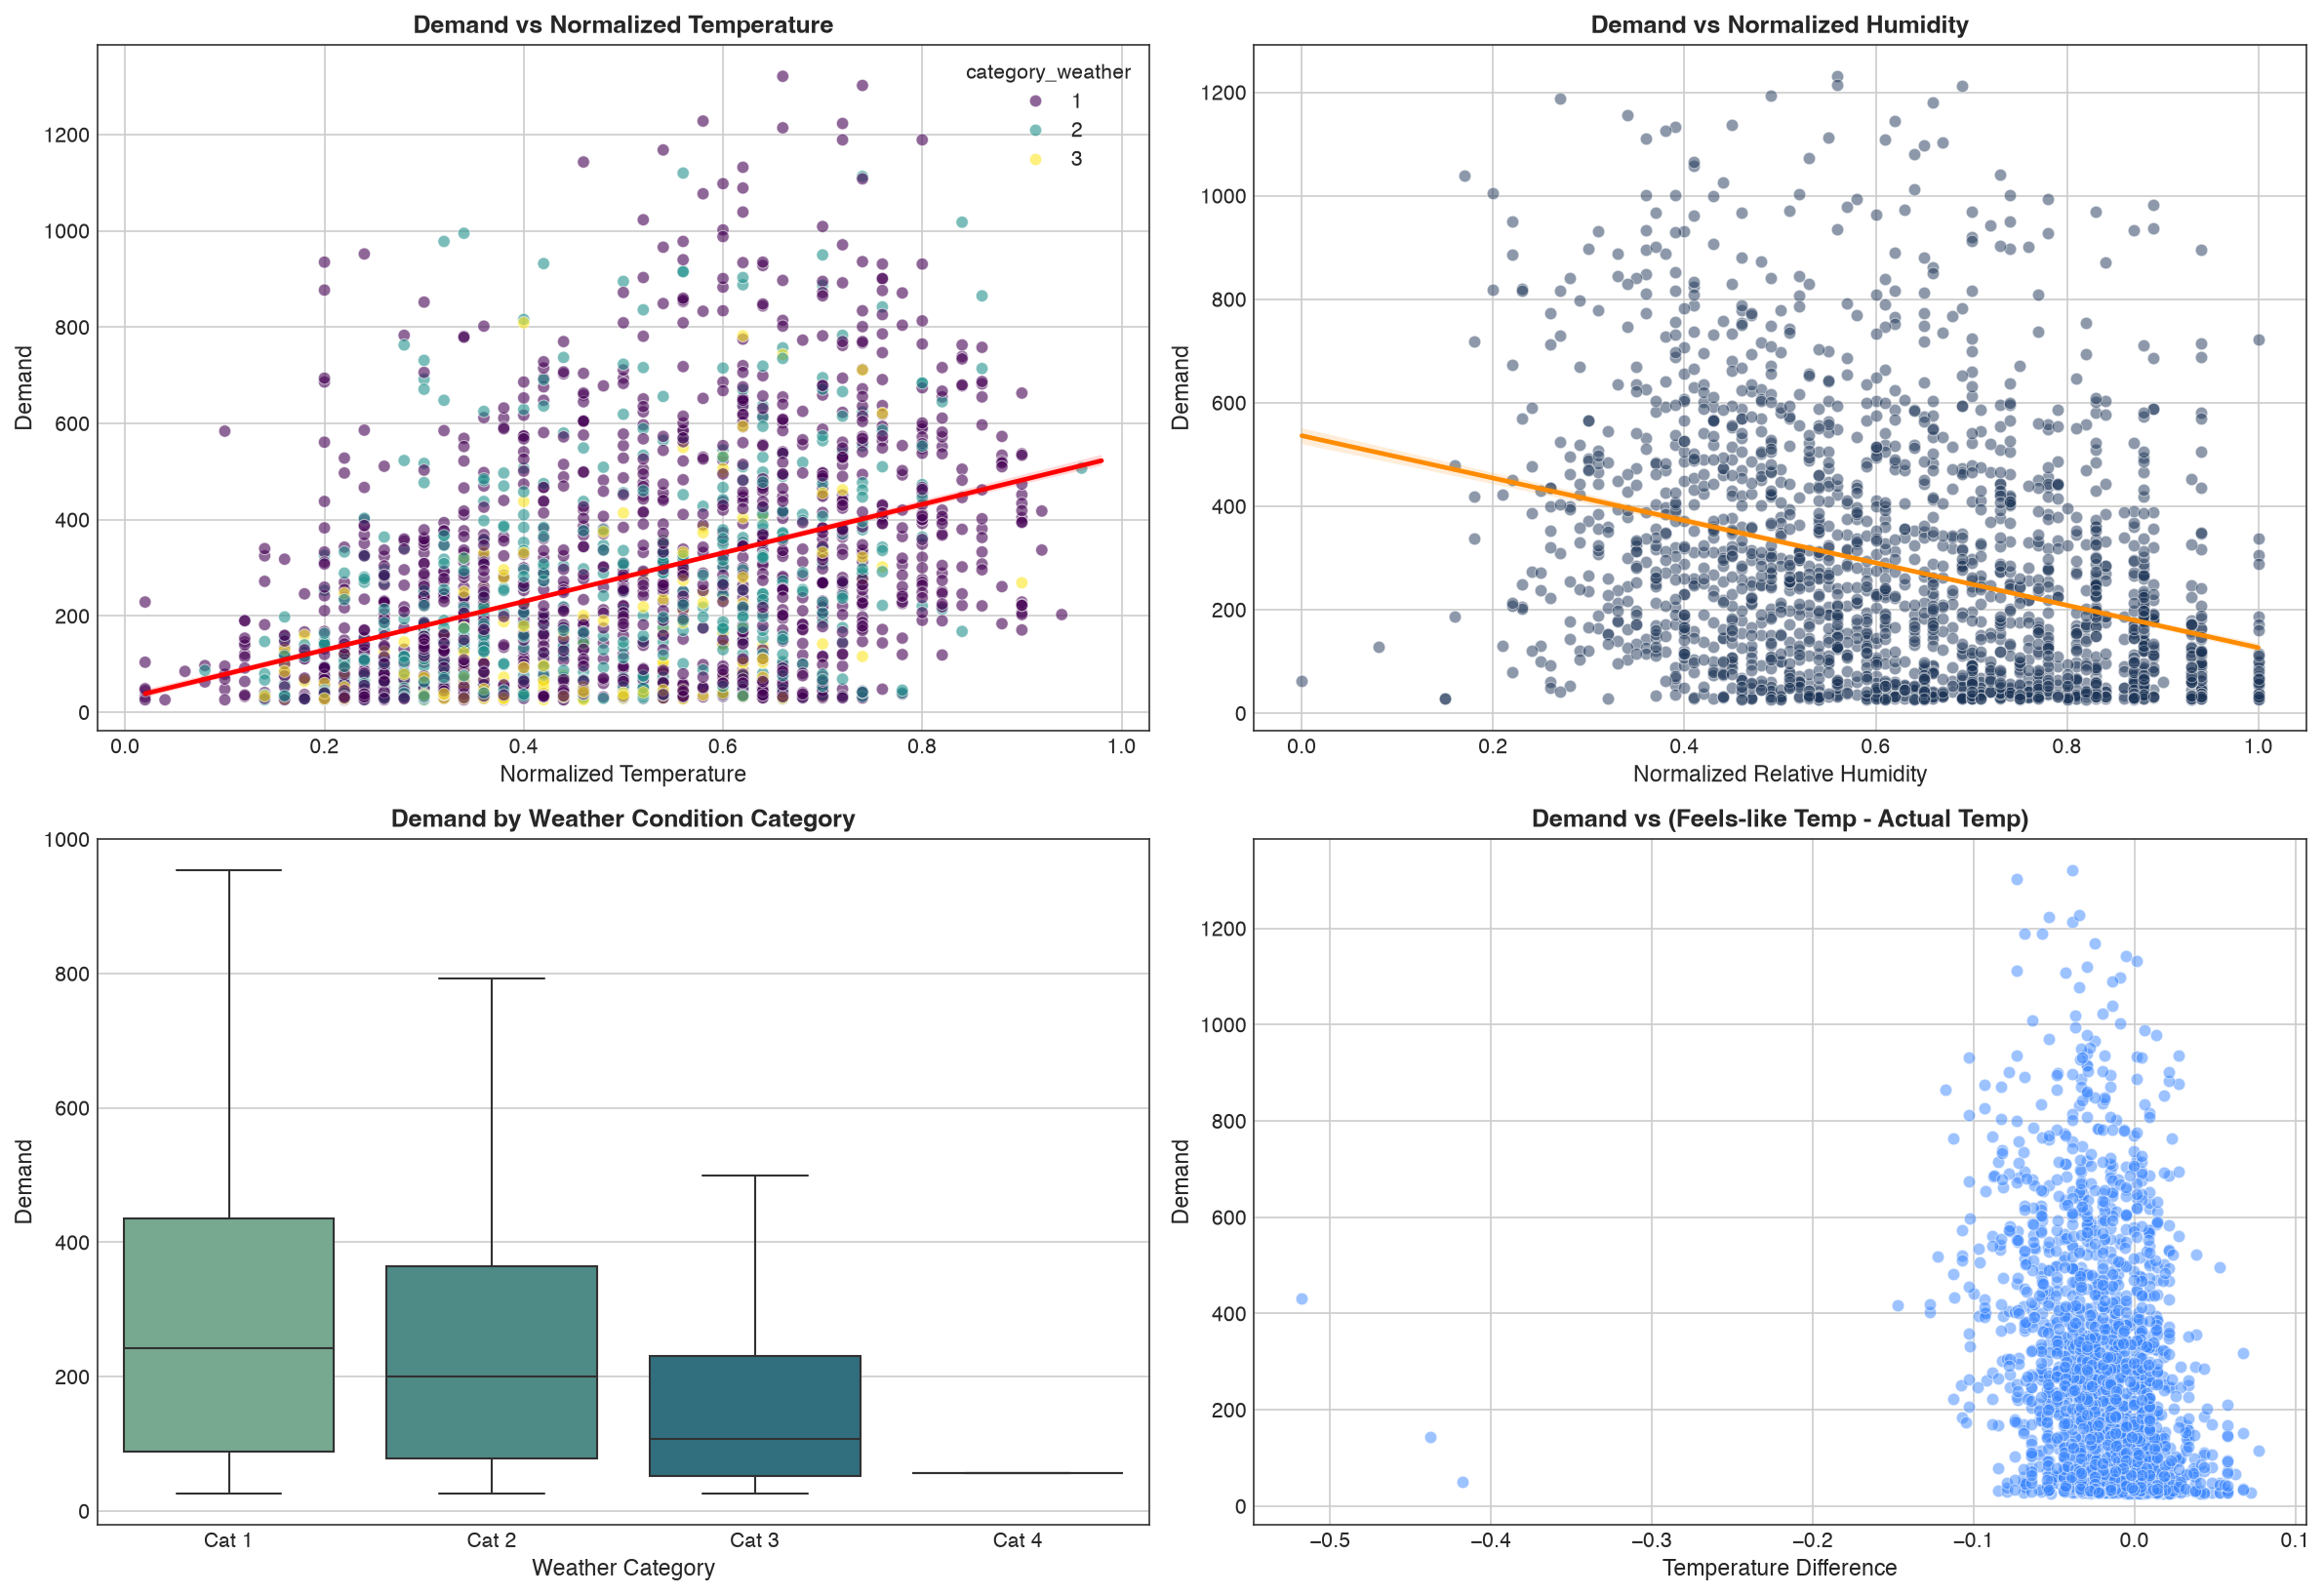

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(16, 11), dpi=150)

# 1. Temperature vs Demand
sns.scatterplot(data=train_df.sample(2000, random_state=42), x='feature_temp', y='demand', hue='category_weather', 
                palette='viridis', alpha=0.6, ax=axes[0, 0])
sns.regplot(data=train_df, x='feature_temp', y='demand', scatter=False, ax=axes[0, 0], color='red')
axes[0, 0].set_title("Demand vs Normalized Temperature", fontsize=12, fontweight='bold')
axes[0, 0].set_xlabel("Normalized Temperature", fontsize=11)
axes[0, 0].set_ylabel("Demand", fontsize=11)

# 2. Humidity vs Demand
sns.scatterplot(data=train_df.dropna(subset=['feature_humidity']).sample(2000, random_state=42), 
                x='feature_humidity', y='demand', alpha=0.5, color='#1d3557', ax=axes[0, 1])
sns.regplot(data=train_df.dropna(subset=['feature_humidity']), x='feature_humidity', y='demand', scatter=False, ax=axes[0, 1], color='darkorange')
axes[0, 1].set_title("Demand vs Normalized Humidity", fontsize=12, fontweight='bold')
axes[0, 1].set_xlabel("Normalized Relative Humidity", fontsize=11)
axes[0, 1].set_ylabel("Demand", fontsize=11)

# 3. Weather Category Boxplot
weather_labels = ['1: Clear/Few Clouds', '2: Mist/Cloudy', '3: Light Rain/Snow', '4: Heavy Rain/Storm']
sns.boxplot(data=train_df, x='category_weather', y='demand', ax=axes[1, 0], palette='crest', showfliers=False)
axes[1, 0].set_title("Demand by Weather Condition Category", fontsize=12, fontweight='bold')
axes[1, 0].set_xlabel("Weather Category", fontsize=11)
axes[1, 0].set_xticklabels([f"Cat {i}" for i in range(1, 5)])
axes[1, 0].set_ylabel("Demand", fontsize=11)

# 4. Temperature Difference (Feels-like vs Actual)
train_df['temp_feel_diff'] = train_df['feature_feel_temp'] - train_df['feature_temp']
sns.scatterplot(data=train_df.sample(2000, random_state=42), x='temp_feel_diff', y='demand', 
                color='#3a86ff', alpha=0.5, ax=axes[1, 1])
axes[1, 1].set_title("Demand vs (Feels-like Temp - Actual Temp)", fontsize=12, fontweight='bold')
axes[1, 1].set_xlabel("Temperature Difference", fontsize=11)
axes[1, 1].set_ylabel("Demand", fontsize=11)

plt.tight_layout()
plt.savefig(PLOTS_DIR / "weather_impact.png", bbox_inches='tight')
plt.show()


## 5. Correlation & Multicollinearity Analysis
Examining linear dependencies among numerical and engineered attributes.


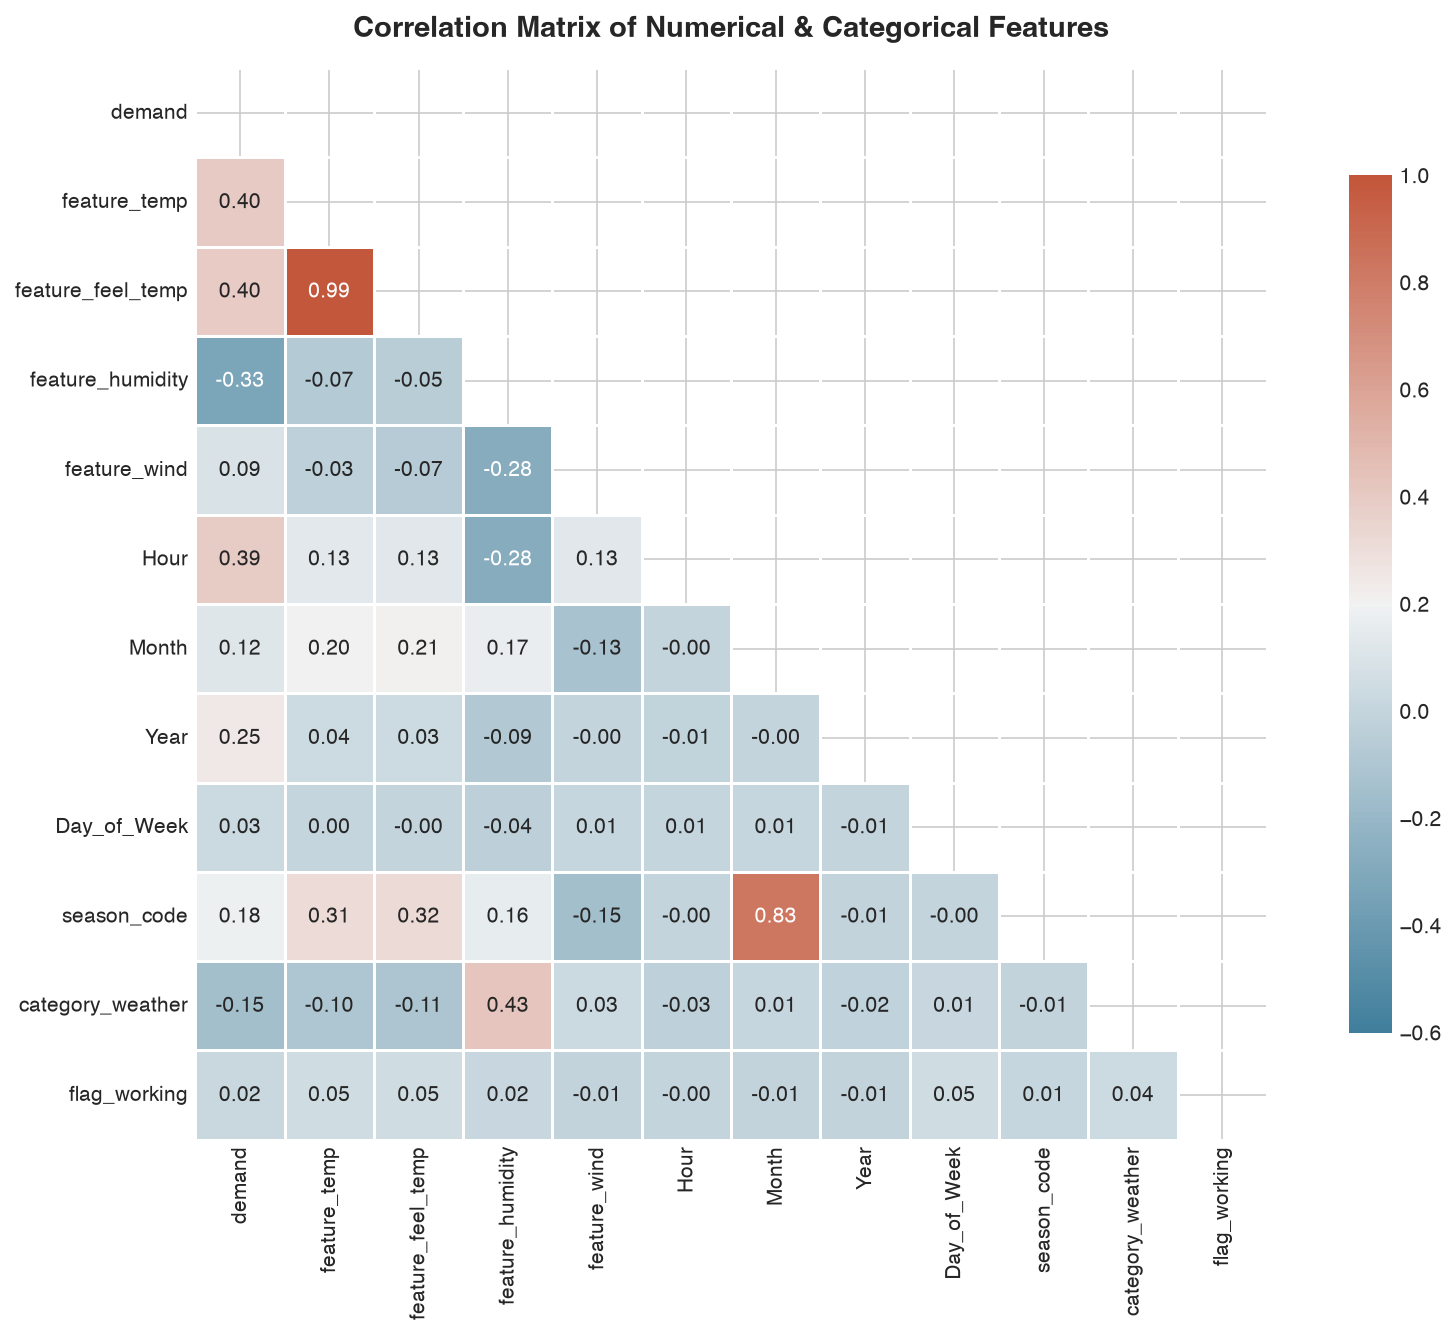

In [7]:
plt.figure(figsize=(12, 9), dpi=150)
num_cols = ['demand', 'feature_temp', 'feature_feel_temp', 'feature_humidity', 'feature_wind', 
            'Hour', 'Month', 'Year', 'Day_of_Week', 'season_code', 'category_weather', 'flag_working']

corr_matrix = train_df[num_cols].corr()
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))

cmap = sns.diverging_palette(230, 20, as_cmap=True)
sns.heatmap(corr_matrix, mask=mask, cmap=cmap, vmin=-0.6, vmax=1.0, annot=True, fmt=".2f",
            square=True, linewidths=0.5, cbar_kws={"shrink": 0.8})

plt.title("Correlation Matrix of Numerical & Categorical Features", fontsize=14, fontweight='bold', pad=15)
plt.tight_layout()
plt.savefig(PLOTS_DIR / "correlation_matrix.png", bbox_inches='tight')
plt.show()


## 6. Key Insights & Modeling Recommendations

### Insights:
1. **Strong Hourly Commuter Seasonality**: Hour is the single strongest predictor of demand. The interaction between `Hour` and `flag_working` separates commuter spikes (8 AM, 5–6 PM) from leisure afternoon peaks (1–4 PM).
2. **Year-over-Year Growth**: 2012 has substantially higher demand across all months than 2011, establishing an upward trend.
3. **Severe Weather Drops**: Adverse weather (`category_weather >= 3`) and high humidity severely depress demand.
4. **Target Distribution**: `demand` is positively skewed ($1.27$). Transforming target with $\log(1+y)$ helps tree models minimize relative percentage errors and improves RMSLE and RMSE on skewed tails.
5. **High Temperature Correlation**: `feature_temp` and `feature_feel_temp` are strongly correlated ($r > 0.98$). Creating a difference feature `temp_feel_diff` captures heat index/wind chill nuance without collinearity issues.
